# Example: KMT-2025-BLG-0811 — a low-mass-ratio planet with four degenerate solutions

This is one of a series of example notebooks that run lenscape's map pipeline, with its default settings, on
published planetary events, and compare the maps with the published ones. This event comes from a different team
and a different modelling code than the Han et al. events of `example_kb200202`, `example_kb230466` and
`example_kb221551`.

**The event.** KMT-2025-BLG-0811 (Tang, Zang et al. 2026, *Two Low Mass-Ratio Microlensing Planets and Two Types of
Central-Resonant Degeneracy*, arXiv:2603.09045) is a high-magnification event that peaked on HJD′ ≈ 10804.67
(HJD′ = HJD − 2450000) with *u*₀ ≈ 0.003. A short bump of about 2.4 hours right after the peak was captured by KMTC
and by the LCOGT telescopes at CTIO and Teide; LCOGT at SAAO covered the dip before it. The paper finds four
solutions with *q* ≈ 4.5 × 10⁻⁵ — the close/wide pairs of a central and a resonant caustic (Δχ² = 0, 1.2, 8.1, 8.2)
— and reports the wide-resonant one as the best.

**Their map.** A grid in (log *s*, log *q*, log ρ, α): first coarse (61 × 61 points over −1.5 ≤ log *s* ≤ 1.5,
−6 ≤ log *q* ≤ 0, nine values of log ρ, 16 starting angles), then dense around the minima (201 × 26 points over
−0.2 ≤ log *s* ≤ 0.2, −5.5 ≤ log *q* ≤ −3.0, 16 values of log ρ). At each point *s*, *q* and ρ are held fixed and
(*t*₀, *u*₀, *t*ₑ, α) are fitted with an MCMC sampler (emcee); the map shows the lowest χ² over ρ. lenscape fits ρ
freely at each point, so both maps show the same profile.

**What is different here.** The public data are the KMTNet survey data only: the 325 LCOGT points of the paper are
not public, and they cover much of the anomaly. Our maps therefore show what the public KMTNet data alone say about
this planet. The paper also used limb darkening (*u*_I = 0.59); lenscape's maps use a uniform source.

**What this notebook does.** It loads the public photometry, normalises the error bars and fits the published
solutions, draws the paper's map (read from its figure), computes our 1× map on the paper's coarse lattice, and
shows why the public data leave *t*ₑ, and with it *q*, almost free.

## 0. Setup

In [1]:
import os, json, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import minimize
import lenscape
from lenscape import figures

RECOMPUTE = False              # True: compute the best fit and all maps again; False: compute only what data/ lacks
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")


def run_or_load(name, compute):
    # data/kb250811_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/kb250811_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/kb250811_photometry.csv` holds the public KMTNet pySIS photometry (field BLG19, *I* band, HJD′ 10740–10870)
of KMTC19, KMTS19 and KMTA19 as it comes from the KMTNet event archive: one row per point with `set`, `t`, `flux`,
`flux_err` and `mag_err`, no error rescaling and no outlier removal. The paper used 960, 412 and 381 KMTNet points
(its own reduction) plus 325 LCOGT points.

In [2]:
rows = np.genfromtxt("data/kb250811_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
SETS = ["KMTC19", "KMTS19", "KMTA19"]
# pySIS Delta_flux falls as the star brightens; flip the sign so that brighter is up. The fit does not care: the
# source and blend fluxes change sign, chi2 is identical.
raw = lenscape.Data.from_sets({n: (rows["t"][rows["set"] == n], -rows["flux"][rows["set"] == n],
                                   rows["flux_err"][rows["set"] == n]) for n in SETS})
raw

Data(1840 points, t 10740.58 .. 10869.99, sets {'KMTC19': 997, 'KMTS19': 467, 'KMTA19': 376})

## 2. Error bars and the best fit

The pySIS error bars are not normalised. As in the papers, we rescale them per data set so that the best fit has
χ²/N = 1 (Yee et al. 2012; here with a factor *k* only, σ′ = *k* σ), and we remove points more than 5σ off the best
fit. The best fit starts from the published solutions (Table below). The papers and lenscape measure the trajectory
angle α and the sign of *u*₀ in different conventions, so each published solution is tried in the four equivalent
forms (α, 2π − α, π − α, α + π) with both signs of *u*₀, and the best start is refined with `lenscape.fit_full`.
Then every published solution is refitted on the final data, which shows how well these data separate them.

The result is stored in `data/kb250811_bestfit.json`; the fits take a few minutes and run only if that file is missing.

In [3]:
SOLUTIONS = {
    "close central": (10804.6649, 0.00319, 50.05, 0.932, 4.397e-5, 5.21417, 0.93e-3),
    "wide central": (10804.6650, 0.00317, 50.53, 1.076, 4.356e-5, 5.21347, 0.92e-3),
    "close resonant": (10804.6652, 0.00320, 49.82, 0.970, 4.522e-5, 5.21609, 0.48e-3),
    "wide resonant": (10804.6651, 0.00328, 48.55, 1.035, 4.663e-5, 5.21487, 0.50e-3),
}          # published: (t0, u0, tE, s, q, alpha [rad], rho); rho None = not measured


def as_vector(sol):
    t0, u0, tE, s, q, al, rho = sol
    return np.array([t0, u0, tE, np.log10(s), np.log10(q), al, np.log10(rho if rho else 1e-3)])


def variants(p):
    out = []
    for sg in (1, -1):
        for a in (p[5], 2 * np.pi - p[5], np.pi - p[5], p[5] + np.pi):
            v = p.copy(); v[1] = sg * abs(p[1]); v[5] = a % (2 * np.pi); out.append(v)
    return out


be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
path = "data/kb250811_bestfit.json"
if RECOMPUTE or not os.path.exists(path):
    log("best fit: starts from the published solutions")
    d = raw
    starts = sorted(((lenscape.model.chi2(be, v, d), name, v) for name, sol in SOLUTIONS.items()
                     for v in variants(as_vector(sol))), key=lambda z: z[0])
    c, p = min((lenscape.fit_full(d, v, rounds=2) for _, _, v in starts[:4]), key=lambda z: z[0])
    r = lenscape.model.residuals(be, p, d)
    keep = np.ones(len(d), bool)
    for k in range(d.nsets):
        m = d.idx == k
        keep[m] = np.abs(r[m]) < 5 * np.sqrt(np.mean(r[m] ** 2))
    d = raw.select(keep)
    kfac = {n: 1.0 for n in d.names}
    for _ in range(3):
        c, p = lenscape.fit_full(d.scale_errors(kfac), p, rounds=2)
        f = lenscape.fit.error_factors(d.scale_errors(kfac), p)
        kfac = {n: kfac[n] * f[n] for n in d.names}
    data = d.scale_errors(kfac)
    c, p = lenscape.fit_full(data, p)
    per_sol = {}
    for name, sol in SOLUTIONS.items():                 # every published solution on the final data
        v = min(variants(as_vector(sol)), key=lambda v: lenscape.model.chi2(be, v, data))
        cs, ps = lenscape.fit_full(data, v, rounds=2)
        per_sol[name] = dict(chi2=cs, p=list(ps))
        log(f"  {name}: chi2 {cs:.1f}")
    name_best = min(per_sol, key=lambda n: per_sol[n]["chi2"])
    if per_sol[name_best]["chi2"] < c:                  # a published solution refits lower: it is the best fit
        c, p = per_sol[name_best]["chi2"], np.array(per_sol[name_best]["p"])
    json.dump(dict(p=list(p), chi2=c, k=kfac, keep=keep.tolist(), N=len(data), solutions=per_sol), open(path, "w"))
bf = json.load(open(path))
data = raw.select(np.array(bf["keep"])).scale_errors(bf["k"])
best = np.array(bf["p"])
chi2_best = lenscape.model.chi2(be, best, data)
print(f"{len(raw) - len(data)} points removed, {len(data)} left; error factors k:",
      ", ".join(f"{n} {v:.2f}" for n, v in bf["k"].items()))
print(f"best fit: chi2 = {chi2_best:.1f} for {len(data)} points;  s = {10 ** best[3]:.4f}, q = {10 ** best[4]:.3e}, "
      f"tE = {best[2]:.2f} d, rho = {10 ** best[6]:.2e}")
print("\npublished solutions refitted on these data:")
for name, s in bf["solutions"].items():
    p = np.array(s["p"])
    if s["chi2"] > 10 * len(data):                      # diverged: the paper's reference point differs from ours
        print(f"  {name:22s} refit from the published values failed (chi2 {s['chi2']:.3g})")
        continue
    print(f"  {name:22s} Delta chi2 = {s['chi2'] - bf['chi2']:7.1f}   log s = {p[3]:+.3f}  log q = {p[4]:+.3f}  "
          f"tE = {p[2]:6.1f} d  log rho = {p[6]:+.2f}")

0 points removed, 1840 left; error factors k: KMTC19 2.42, KMTS19 2.26, KMTA19 2.14
best fit: chi2 = 1840.0 for 1840 points;  s = 1.1262, q = 3.784e-06, tE = 964.71 d, rho = 5.32e-05

published solutions refitted on these data:
  close central          Delta chi2 =     0.1   log s = -0.051  log q = -5.232  tE =  618.8 d  log rho = -4.08
  wide central           Delta chi2 =     0.0   log s = +0.052  log q = -5.422  tE =  964.7 d  log rho = -4.27
  close resonant         Delta chi2 =     0.5   log s = -0.018  log q = -5.141  tE =  411.7 d  log rho = -4.10
  wide resonant          Delta chi2 =     0.5   log s = +0.018  log q = -5.194  tE =  466.6 d  log rho = -4.15


The paper's Δχ² between the four solutions (8.1, 8.2, 1.2 and 0) came from data that include the LCOGT points. The
table above shows how far the public KMTNet data alone separate them.

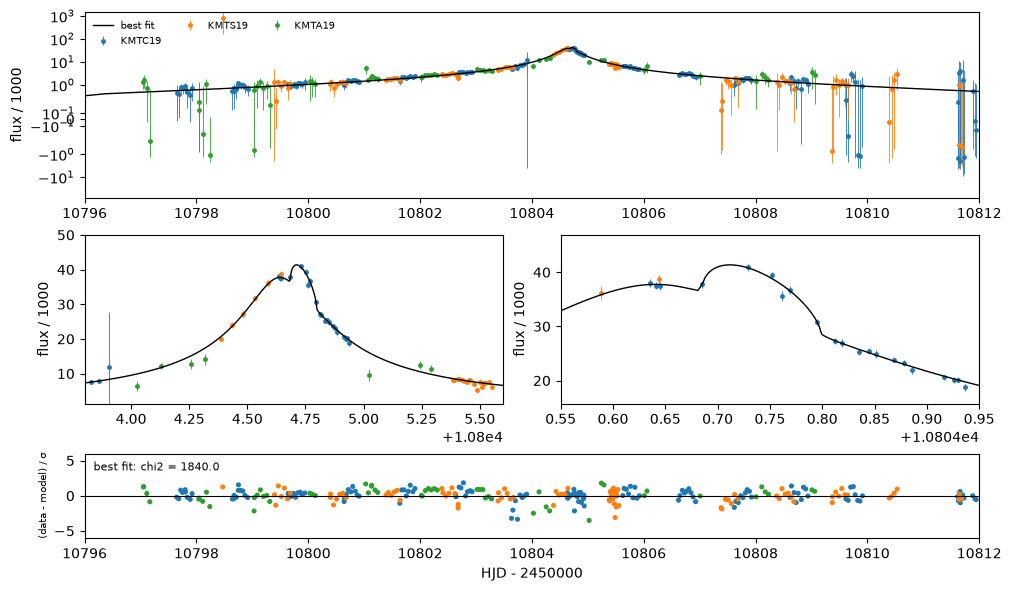

In [4]:
WINDOW, ZOOMS = (10796.0, 10812.0), ((10803.8, 10805.6), (10804.55, 10804.95))


def plot_flux(sols, window=WINDOW, zooms=ZOOMS, d=None):
    # data of all sets on the flux scale of the first set (aligned with the best fit), the first set's model of each
    # solution, two zooms and one panel of normalised residuals per solution (each with its own fluxes); the top
    # panel has a symmetric-log flux axis
    d = data if d is None else d
    styles = ["-", ":", "--", "-.", (0, (5, 1)), (0, (1, 3))]
    fs0, fb0 = lenscape.model.fluxes(lenscape.model.magnification(be, best, d), d)
    fig = plt.figure(figsize=(10, 4.8 + 1.0 * len(sols)), constrained_layout=True)
    gs = fig.add_gridspec(2 + len(sols), 2, height_ratios=[2.2, 2.0] + [1] * len(sols))
    top = fig.add_subplot(gs[0, :]); zax = [fig.add_subplot(gs[1, k]) for k in range(2)]
    for ax, (a, b) in zip([top] + zax, [window] + list(zooms)):
        lo, hi = [], []
        tt = np.linspace(a, b, 4000)
        for (name, p), ls in zip(sols.items(), styles):
            fs, fb = lenscape.model.fluxes(lenscape.model.magnification(be, p, d), d)
            mod = (fs[0] * be.lc(lenscape.model.clamp(p)[0], tt) + fb[0]) / 1e3
            ax.plot(tt, mod, linestyle=ls, color="k", lw=1, label=name if ax is top else None, zorder=3)
            lo.append(mod.min()); hi.append(mod.max())
        for k, name in enumerate(d.names):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            f = (d.f[m] - fb0[k]) / fs0[k] * fs0[0] + fb0[0]
            ax.errorbar(d.t[m], f / 1e3, d.e[m] * abs(fs0[0] / fs0[k]) / 1e3, fmt="o", ms=2.5, lw=0.6,
                        color=f"C{k}", label=name if ax is top else None, zorder=2)
        span = max(hi) - min(lo)
        ax.set_xlim(a, b); ax.set_ylabel("flux / 1000")
        if ax is not top:
            ax.set_ylim(min(lo) - 0.15 * span, max(hi) + 0.25 * span)
    top.set_yscale("symlog", linthresh=max(abs(fb0[0] + fs0[0]) / 1e3, 0.1))
    top.legend(fontsize=7, frameon=False, ncol=3, loc="upper left")
    for k, (name, p) in enumerate(sols.items()):
        ax = fig.add_subplot(gs[2 + k, :], sharex=top)
        r = lenscape.model.residuals(be, p, d)
        m = (d.t > window[0]) & (d.t < window[1])
        ax.scatter(d.t[m], r[m], s=7, c=[f"C{i}" for i in d.idx[m]]); ax.axhline(0, color="k", lw=0.8)
        ax.set_ylim(-6, 6); ax.set_ylabel("(data - model) / σ", fontsize=7)
        ax.text(0.01, 0.8, f"{name}: chi2 = {np.sum(r ** 2):.1f}", transform=ax.transAxes, fontsize=8)
    ax.set_xlabel(f"HJD - {2450000}")
    return fig

plot_flux({"best fit": best});

For later comparison, here is the **single-lens floor**: the χ² of the best point-lens model (with a finite source),
measured against the binary best fit. Points of a map with Δχ² near this value are no better than having no planet
or companion at all.

In [5]:
def chi2_1l1s(x):
    A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]), 10 ** x[3], data.t, 0.0)
    fs, fb = lenscape.model.fluxes(A, data)
    return float((((data.f - fs[data.idx] * A - fb[data.idx]) / data.e) ** 2).sum())

chi2_single = min(minimize(chi2_1l1s, [best[0], u0, best[2], lr], method="Nelder-Mead",
                           options=dict(maxfev=4000, adaptive=True)).fun
                  for u0 in (0.001, 0.003, 0.01, 0.03, 0.1, 0.3) for lr in (-3.5, -2.5, -1.5))
floor = chi2_single - chi2_best
print(f"single-lens floor: Delta chi2 = {floor:.1f}")

single-lens floor: Delta chi2 = 88.2


On the public data the single-lens floor is 88: a point lens with a finite source is only 88 worse than the binary
best fit. The paper's maps reach Δχ² = 432 and beyond; with the LCOGT points over the anomaly its planetary signal is
much stronger. Our maps below therefore stay under about 90 wherever a nearly single-lens model is possible, which
is almost everywhere with small *q*.

## 3. The paper's map

`data/kb250811_paper_grid.csv` holds the paper's Fig. 3, read from the figure: the panels embed each map as an
indexed-colour image, which we sample at the grid points given in the text. The
bands are Δχ² < 12 *k*² for *k* = 1…6 (*n*² = 12 in the caption); grid points above 432 are not shown.

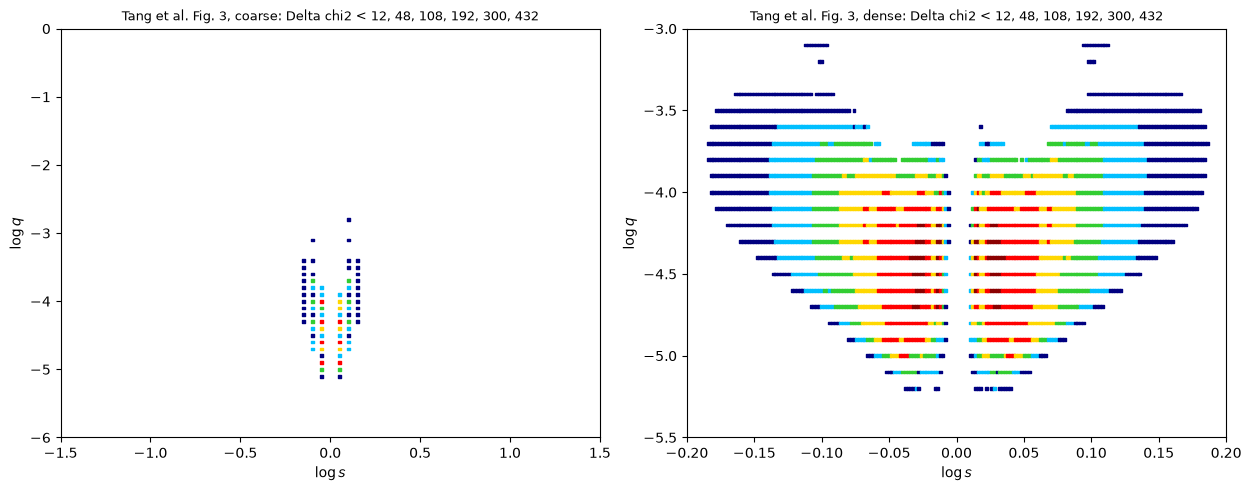

In [6]:
paper = np.genfromtxt("data/kb250811_paper_grid.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                      skip_header=2)
EDGES = np.array([12, 48, 108, 192, 300, 432])                         # the paper's band edges in Delta chi2
band_cmap = ListedColormap(["#8b0000", "red", "gold", "limegreen", "deepskyblue", "navy"] + ["white"])        # the paper's band colours, white above the last band
PANELS = {"coarse": ((-1.5, 1.5), (-6.0, 0.0)), "dense": ((-0.2, 0.2), (-5.5, -3.0))}                                 # paper panel: (log s range, log q range)
fig, axs = plt.subplots(1, len(PANELS), figsize=(6.2 * len(PANELS), 4.8), constrained_layout=True, squeeze=False)
for ax, (panel, (sr, qr)) in zip(axs[0], PANELS.items()):
    sel = paper["panel"] == panel
    ax.scatter(paper["log_s"][sel], paper["log_q"][sel], c=paper["band"][sel] - 1, cmap=band_cmap, vmin=-0.5,
               vmax=len(EDGES) + 0.5, marker="s", s=4)
    ax.set_xlim(*sr); ax.set_ylim(*qr); ax.set_xlabel(r"$\log s$"); ax.set_ylabel(r"$\log q$")
    ax.set_title(f"Tang et al. Fig. 3, {panel}: Delta chi2 < " + ", ".join(f"{e:g}" for e in EDGES), fontsize=9)

## 4. Our 1× maps on the paper's lattices

`lenscape.lattice` with all defaults on the paper's two grids: the coarse 61 × 61 lattice and, independently and also
from scratch, the dense 201 × 26 lattice. Both are stored in `data/`, so after the first run the notebook only loads
them. After inspecting the coarse map we did not compute the dense lattice (`COMPUTE_DENSE`); the last section says
why.

In [7]:
LS_C, LQ_C = np.linspace(-1.5, 1.5, 61), np.linspace(-6.0, 0.0, 61)      # coarse grid of the paper
LS_D, LQ_D = np.linspace(-0.2, 0.2, 201), np.linspace(-5.5, -3.0, 26)    # dense grid of the paper
coarse = run_or_load("coarse_1x", lambda: lenscape.lattice(data, LS_C, LQ_C, best=best, log=log))
OURS = [("coarse 1x", coarse, "coarse")]
COMPUTE_DENSE = False      # not computed: the public data cannot reproduce the paper's dense map (last section)
if COMPUTE_DENSE or os.path.exists("data/kb250811_map_dense_1x.npz"):
    dense = run_or_load("dense_1x", lambda: lenscape.lattice(data, LS_D, LQ_D, best=best, log=log))
    OURS.append(("dense 1x", dense, "dense"))
for name, m, _ in OURS:
    print(f"{name}: {m['chi2'].shape[0]} x {m['chi2'].shape[1]} points, wall time {m['wall'] / 60:.0f} min")

coarse 1x: 61 x 61 points, wall time 799 min


### Our map next to the paper's

Each of our maps in the paper's bands (same band edges, no rescaling of Δχ²; the reference is the lower of our best
fit and our map minimum), next to the paper's panel of the same region:

coarse 1x: 76 coloured paper points; our band the same at 0 %, within one band at 9 %, above the last band at 0 %


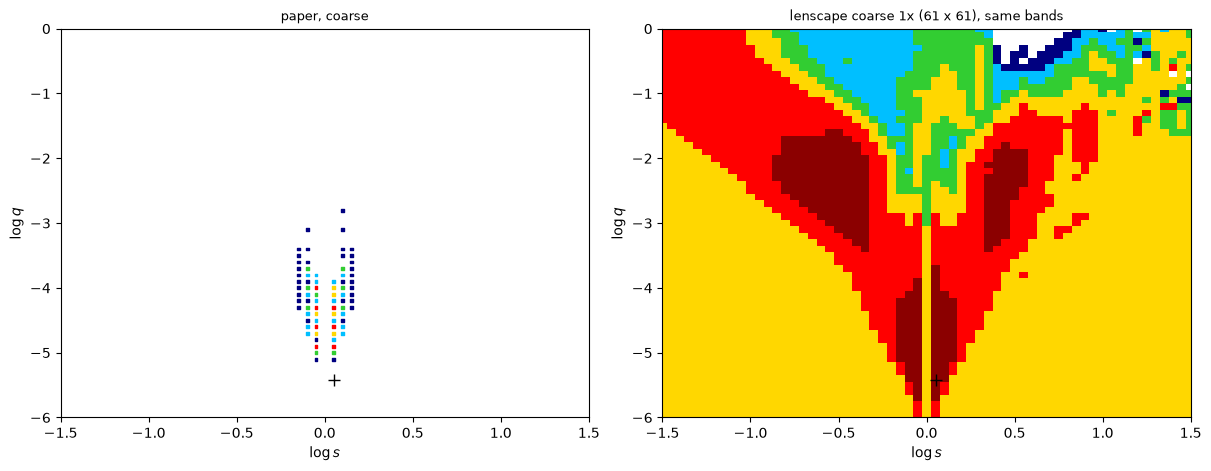

In [8]:
def lowest_ref():
    return min([chi2_best] + [float(np.nanmin(m["chi2"])) for _, m, _ in OURS])

ref = lowest_ref()
fig, axs = plt.subplots(len(OURS), 2, figsize=(12, 4.6 * len(OURS)), constrained_layout=True, squeeze=False)
for row, (name, m, panel) in enumerate(OURS):
    sr, qr = PANELS[panel]
    sel = paper["panel"] == panel
    axs[row, 0].scatter(paper["log_s"][sel], paper["log_q"][sel], c=paper["band"][sel] - 1, cmap=band_cmap,
                        vmin=-0.5, vmax=len(EDGES) + 0.5, marker="s", s=4)
    axs[row, 0].set_title(f"paper, {panel}", fontsize=9)
    band = np.searchsorted(EDGES, m["chi2"] - ref)
    axs[row, 1].pcolormesh(m["logs"], m["logq"], band.T, cmap=band_cmap, vmin=-0.5, vmax=len(EDGES) + 0.5,
                           shading="nearest")
    axs[row, 1].set_title(f"lenscape {name} ({m['chi2'].shape[0]} x {m['chi2'].shape[1]}), same bands", fontsize=9)
    for ax in axs[row]:
        ax.set_xlim(*sr); ax.set_ylim(*qr); ax.set_xlabel(r"$\log s$"); ax.set_ylabel(r"$\log q$")
        ax.plot(best[3], best[4], "k+", ms=9)

# our band at each coloured point of the paper (nearest lattice point inside our map)
for name, m, panel in OURS:
    sel = (paper["panel"] == panel) & (paper["log_s"] >= m["logs"][0]) & (paper["log_s"] <= m["logs"][-1]) \
          & (paper["log_q"] >= m["logq"][0]) & (paper["log_q"] <= m["logq"][-1])
    i = np.round((paper["log_s"][sel] - m["logs"][0]) / (m["logs"][1] - m["logs"][0])).astype(int)
    j = np.round((paper["log_q"][sel] - m["logq"][0]) / (m["logq"][1] - m["logq"][0])).astype(int)
    ours = np.searchsorted(EDGES, m["chi2"][i, j] - ref) + 1
    pb = paper["band"][sel]
    print(f"{name}: {sel.sum()} coloured paper points; our band the same at {100 * np.mean(ours == pb):.0f} %, within "
          f"one band at {100 * np.mean(abs(ours - pb) <= 1):.0f} %, above the last band at {100 * np.mean(ours > len(EDGES)):.0f} %")

The **level** cannot agree. In the paper's coarse map only a small box around log *s* = 0 (|log *s*| ≤ 0.15,
log *q* = −5.1 to −2.8) lies below 432; everything else is white. In ours, 85 % of the plane lies below 108 and 99 %
below 432, because a planet with small *q* or far from the Einstein ring reduces to the single lens, 88 worse. The
band agreement (0 % in the same band, 9 % within one band) measures the missing LCOGT data, not the map.

The **pattern** differs too:
* the valley at log *s* ≈ ±0.05 runs down to log *q* ≈ −5.4, about one dex below the paper's solutions
  (log *q* ≈ −4.35); the next section shows why (*t*ₑ);
* two lobes at log *s* ≈ ±0.45, log *q* ≈ −3.5 to −1.8 fit as well as the valley. They are not in the paper's map.

### Accuracy of the map values

The maps are computed with lenscape's fast grid backend (relative magnification accuracy about 3 × 10⁻³); the best
fit uses the accurate refine backend. Where many precise points sit at high magnification, the difference can reach a
few χ², which matters for band edges of 4 and 9. Here every map point is evaluated again with the refine backend at
its stored parameters (no refit: an upper bound on the accurate profile χ²), and the band comparison is repeated.
Stored in `data/`; this takes a minute or two.

In [9]:
be_exact = lenscape.make_backend(lenscape.config.REFINE_BACKEND)


def exact_chi2(name, m):
    path = f"data/kb250811_map_{name.replace(' ', '_')}_exact.npy"
    if not RECOMPUTE and os.path.exists(path):
        return np.load(path)
    ex = np.empty_like(m["chi2"])
    for i, ls in enumerate(m["logs"]):
        for j, lq in enumerate(m["logq"]):
            t0, u0, tE, al, lr = m["pars"][i, j]
            ex[i, j] = lenscape.model.chi2(be_exact, np.array([t0, u0, tE, ls, lq, al, lr]), data)
    np.save(path, ex)
    return ex


for name, m, panel in OURS:
    ex = exact_chi2(name, m)
    dd = (ex - m["chi2"])[m["chi2"] - ref < EDGES[-1]]
    print(f"{name}: accurate minus map chi2 where Delta chi2 < {EDGES[-1]:g}: median {np.median(dd):+.2f}, "
          f"5-95 % {np.percentile(dd, 5):+.2f} .. {np.percentile(dd, 95):+.2f}; accurate minimum {ex.min():.2f} "
          f"(map {np.nanmin(m['chi2']):.2f}, best fit {chi2_best:.2f})")
    rex = min(chi2_best, ex.min())
    sel = (paper["panel"] == panel) & (paper["log_s"] >= m["logs"][0]) & (paper["log_s"] <= m["logs"][-1]) \
          & (paper["log_q"] >= m["logq"][0]) & (paper["log_q"] <= m["logq"][-1])
    i = np.round((paper["log_s"][sel] - m["logs"][0]) / (m["logs"][1] - m["logs"][0])).astype(int)
    j = np.round((paper["log_q"][sel] - m["logq"][0]) / (m["logq"][1] - m["logq"][0])).astype(int)
    ours = np.searchsorted(EDGES, ex[i, j] - rex) + 1
    pb = paper["band"][sel]
    print(f"   with accurate values: band the same at {100 * np.mean(ours == pb):.0f} %, within one band at "
          f"{100 * np.mean(abs(ours - pb) <= 1):.0f} %, above the last band at {100 * np.mean(ours > len(EDGES)):.0f} %")

coarse 1x: accurate minus map chi2 where Delta chi2 < 432: median +4.04, 5-95 % -0.00 .. +44.14; accurate minimum 1840.01 (map 1839.81, best fit 1840.00)
   with accurate values: band the same at 0 %, within one band at 9 %, above the last band at 0 %


The grid backend is less accurate for this event than for the others: evaluated with the accurate backend, the
points rise by 4 (median) and by up to 44 at 5 % of them. The source is very small here (ρ ≈ 10⁻⁴ to 10⁻³) and the
peak magnification high. The minimum moves by only 0.2. The plateau moves most: on map values 80 % of the plane
lies below the single-lens floor of 88, on accurate values 46 %, so most of the plateau really sits at the floor.

### Local minima of our map

Lattice points lower than all eight neighbours, with their Δχ² and fitted parameters, next to the published
solutions:

In [10]:
def local_minima(m, max_dchi2):
    c = m["chi2"]; out = []
    for i in range(1, c.shape[0] - 1):
        for j in range(1, c.shape[1] - 1):
            nb = c[i - 1:i + 2, j - 1:j + 2]
            if m.get("folded") and m["logq"][j] > 1e-9:
                continue                                   # folded map: the mirror half repeats the minima
            if c[i, j] <= nb.min() and c[i, j] - ref < max_dchi2:
                out.append((c[i, j] - ref, m["logs"][i], m["logq"][j], m["pars"][i, j]))
    return sorted(out, key=lambda z: z[0])

for name, m, panel in OURS:
    print(f"{name}:")
    for dc, ls, lq, x in local_minima(m, EDGES[-1])[:15]:
        print(f"  Delta chi2 {dc:7.1f}  log s {ls:+.3f}  log q {lq:+.3f}  tE {abs(x[2]):6.1f} d  log rho {x[4]:+.2f}")

coarse 1x:
  Delta chi2     0.0  log s -0.400  log q -2.700  tE  274.3 d  log rho -3.13
  Delta chi2     0.2  log s -0.450  log q -2.400  tE  175.4 d  log rho -2.94
  Delta chi2     0.2  log s -0.050  log q -5.400  tE  904.4 d  log rho -4.25
  Delta chi2     0.2  log s +0.050  log q -5.400  tE  902.7 d  log rho -4.25
  Delta chi2     0.5  log s -0.400  log q -3.100  tE  681.6 d  log rho -3.53
  Delta chi2     0.8  log s +0.400  log q -3.000  tE  533.2 d  log rho -3.42
  Delta chi2     1.2  log s +0.450  log q -2.600  tE  286.1 d  log rho -3.15
  Delta chi2     1.3  log s +0.450  log q -2.400  tE  170.4 d  log rho -2.92
  Delta chi2     6.0  log s +0.550  log q -2.100  tE  151.7 d  log rho -2.88
  Delta chi2    13.7  log s +0.550  log q -1.600  tE   64.6 d  log rho -2.50
  Delta chi2    16.4  log s -1.450  log q -0.600  tE  294.3 d  log rho -3.18
  Delta chi2    16.5  log s -1.450  log q -0.800  tE  401.5 d  log rho -3.32
  Delta chi2    16.9  log s +1.400  log q -1.200  tE  142.0 d  lo

In [11]:
print("published solutions (Table of the paper):")
for name, sol in SOLUTIONS.items():
    print(f"  {name:22s} log s {np.log10(sol[3]):+.3f}  log q {np.log10(sol[4]):+.3f}  tE {sol[2]:6.1f} d")

published solutions (Table of the paper):
  close central          log s -0.031  log q -4.357  tE   50.0 d
  wide central           log s +0.032  log q -4.361  tE   50.5 d
  close resonant         log s -0.013  log q -4.345  tE   49.8 d
  wide resonant          log s +0.015  log q -4.331  tE   48.5 d


**All low minima are equally good.** The valley at log *s* = ±0.05, log *q* = −5.4 and the lobes at
log *s* ≈ −0.45 and +0.45, log *q* ≈ −3.1 to −2.4 are all within 1.3 of the best fit. In the lobes the planet sits
farther from the Einstein ring (*s* ≈ 0.35 or 2.8) and *q* is larger, which gives a central caustic of similar size
in time. The public data have 23 points in the 0.4 days of the anomaly (14 in its central 0.25 days), not enough to
tell these caustics apart.

**The published solutions are not minima of this map.** Refitted on the public data, all four lie within 0.5 of
the best fit (Section 2), but with *t*ₑ = 410 to 960 d instead of 50 d, and with log *q* about one dex lower. The
next section shows that *t*ₑ is almost unconstrained by these data.

## The *t*ₑ degeneracy

Near the peak of a high-magnification event *u* ≪ 1 and *A* ≈ 1/*u*. The flux *f*ₛ*A* + *f*_b then depends only on
*t*₀, *u*₀*t*ₑ and *f*ₛ*t*ₑ: a longer *t*ₑ with a fainter source gives the same peak. Only the wings, where
|*t* − *t*₀| approaches *t*ₑ, can break this, and with these error bars they hardly do. The anomaly scales in the same
way: its duration fixes *q t*ₑ (central caustic) and ρ*t*ₑ (source crossing), not *q* and ρ separately.

The cell below fits the binary with *t*ₑ held fixed (*s*, *q*, ρ, *t*₀, *u*₀ and α free, started from the refitted
published solutions with *u*₀*t*ₑ and *q t*ₑ kept). It is cached in `data/kb250811_te_profile.json`.

In [12]:
path = "data/kb250811_te_profile.json"
if RECOMPUTE or not os.path.exists(path):
    log("tE profile")
    starts = [np.array(s["p"]) for s in bf["solutions"].values()] + [best]
    prof = []
    for tE in (50.0, 100.0, 200.0, 400.0, float(best[2])):
        res = []
        for p0 in starts:
            x0 = p0.copy(); f = p0[2] / tE
            x0[1] *= f; x0[4] += np.log10(f)                 # keep u0 tE and q tE
            free = [0, 1, 3, 4, 5, 6]

            def fun(y):
                x = x0.copy(); x[free] = y; x[2] = tE
                return lenscape.model.chi2(be, x, data)
            y = x0[free]
            for _ in range(3):
                r = minimize(fun, y, method="Nelder-Mead", options=dict(maxfev=3000, adaptive=True, xatol=1e-7, fatol=1e-3))
                y = r.x
            res.append((float(r.fun), list(y)))
        c, y = min(res, key=lambda z: z[0])
        prof.append(dict(tE=tE, chi2=c, logs=y[2], logq=y[3], logrho=y[5], u0=y[1]))
    json.dump(prof, open(path, "w"))
prof = json.load(open(path))
print(" tE [d]   Delta chi2   log s    log q   log rho   u0 tE [d]   q tE [d]")
for r in prof:
    print(f"{r['tE']:7.1f}   {r['chi2'] - chi2_best:8.1f}   {r['logs']:+.3f}   {r['logq']:+.3f}   {r['logrho']:+.2f}"
          f"   {abs(r['u0']) * r['tE']:9.3f}   {10 ** r['logq'] * r['tE']:.5f}")
print(f"published: tE = 50 d, log q = -4.36, u0 tE = {0.00319 * 50.05:.3f} d, q tE = {4.4e-5 * 50:.5f} d")

 tE [d]   Delta chi2   log s    log q   log rho   u0 tE [d]   q tE [d]
   50.0       14.0   +0.053   -4.132   -2.99       0.170   0.00369
  100.0        3.4   +0.052   -4.436   -3.29       0.169   0.00367
  200.0        0.8   +0.052   -4.739   -3.59       0.169   0.00365
  400.0        0.2   +0.052   -5.040   -3.89       0.169   0.00365
  964.7        0.0   +0.052   -5.422   -4.27       0.169   0.00365
published: tE = 50 d, log q = -4.36, u0 tE = 0.160 d, q tE = 0.00220 d


The paper's *t*ₑ = 50 d costs only Δχ² ≈ 14 on the public data, and *t*ₑ = 100 d about 3. Along the profile
*u*₀*t*ₑ and *q t*ₑ stay constant, so log *q* falls by 1.3 dex as *t*ₑ grows from 50 to 965 d, which is the valley of
our map. Even at *t*ₑ = 50 d the public data give log *q* = −4.1, not the paper's −4.36: *q t*ₑ itself is set by the
few anomaly points. The lower end of our valley (log *q* ≈ −5.5) is set by lenscape's bound *t*ₑ ≤ 1000 d (24 % of
the map's points sit on it), not by the data.

## Why we do not densify this map

For the other examples the next step was a 2× densify or a zoom. Here it would cost most of a day and could not
reproduce the paper's map:

* **The data, not the lattice, limit the map.** Without the LCOGT points a single lens is only 88 worse than the
  best fit, so the whole low-*q* plane lies below the paper's third band (108). Finer sampling cannot recover the
  paper's contrast, which comes from data we do not have.
* **The planet's parameters are degenerate on these data.** *t*ₑ is free along the valley (Δχ² < 4 for
  *t*ₑ = 100 to 1000 d), and *q* moves with it. A finer lattice would sample the same degenerate valley more
  densely; it would not move its minimum to the paper's solution.
* **The minima cannot be ranked.** The central valley and the two lobes at log *s* ≈ ±0.45 lie within 1.3 of each
  other, while the grid backend's error here is 4 (median) and up to 44. Ranking them needs the accurate backend,
  not more lattice points.
* **The structure is resolved.** The valley and the lobes each span several coarse lattice points.
* **Cost.** The paper's dense lattice (201 × 26 = 5226 points) takes about 19 hours on 20 threads at the rate of the
  coarse map; the valley would also run out of its lower edge (log *q* = −5.5).

The paper's ranking of its four solutions, and its *t*ₑ and *q*, rest on the LCOGT data. With public data only, a
comparable map would need a constraint on *t*ₑ or on the source flux (for example from the source colour and
magnitude), which lenscape's maps do not take.